# Member 1 — Word-overlap analysis notebook (Part 1)

This notebook turns the **saved** results of `run_grid.py` into report-ready figures and tables.

**It never recomputes the experiment.** Every number shown here is read from `results/m1/`, which
`run_grid.py` wrote. The only live computations are the pipeline illustration (section 5), which runs
`factcheck.py` on one example, and the optional official run (section 7). This keeps a single source of truth:
if a number appears in the report, it came from `run_grid.py`.

**Order to run things (from the repository root):**
1. `python -m unittest discover -s experiments/m1_preprocessing -v` (tests)
2. `python experiments/m1_preprocessing/run_grid.py --data_dir data --out_dir results/m1` (experiment)
3. Open this notebook and run **Kernel → Restart & Run All**. Figures are saved to `report/figures/m1_*.png`.

| Section | What it shows | Figure file |
|---|---|---|
| 1 | Best AUC for each similarity metric, with 95% bootstrap CIs | `m1_auc_by_metric.png` |
| 2 | Ablation: what each design decision is worth | `m1_ablation.png` |
| 3 | ROC curves for recall, Jaccard and TF-IDF cosine | `m1_roc_curves.png` |
| 4 | Score distributions for Supported vs Not Supported facts | `m1_score_distributions.png` |
| 5 | Preprocessing pipeline example and execution-time comparison | `m1_preprocessing_time.png` |
| 6 | Error analysis and confusion matrix at the diagnostic threshold | `m1_confusion_oracle.png` |
| 7 | Official `factchecking_main.py --mode word_overlap` run (once Member 2's `predict()` exists) | — |

In [1]:
# ---------------------------------------------------------------------------------------------------------------
# Setup: paths, plotting style and a helper to save figures.
# ---------------------------------------------------------------------------------------------------------------
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# This notebook lives in experiments/m1_preprocessing/, so the repository root is two folders up.
NOTEBOOK_DIR = os.path.abspath("")
REPO_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, "..", ".."))
RESULTS_DIR = os.path.join(REPO_ROOT, "results", "m1")     # written by run_grid.py (git-ignored)
FIG_DIR = os.path.join(REPO_ROOT, "report", "figures")     # report figures (tracked by git)
# The dataset is not in git. Point CM3604_DATA_DIR at it if it is not in <repo>/data.
DATA_DIR = os.environ.get("CM3604_DATA_DIR", os.path.join(REPO_ROOT, "data"))
os.makedirs(FIG_DIR, exist_ok=True)
sys.path.insert(0, REPO_ROOT)       # so we can import factcheck.py
sys.path.insert(0, NOTEBOOK_DIR)    # so we can import run_grid.py

if not os.path.exists(os.path.join(RESULTS_DIR, "scores_all.csv")):
    raise FileNotFoundError("No results found in " + RESULTS_DIR + ". Run run_grid.py first (see the table above).")

# Colours: a colour-blind-safe categorical palette, used with the same meaning in every figure.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # BLUE = Supported / main series, ORANGE = Not Supported
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"     # text, secondary text / neutral marks, grid lines
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

def save(fig, name):
    # Save a figure for the report: white background, tight bounding box, 200 dpi.
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print("saved", os.path.relpath(path, REPO_ROOT))

METRIC_LABELS = {"recall": "Recall", "idf_recall": "IDF-weighted recall", "tfidf_cosine": "TF-IDF cosine",
                 "f1": "F1", "jaccard": "Jaccard", "precision": "Precision"}
print("Repository:", REPO_ROOT)

Repository: D:\IIT\Third year\DL\DL_CW\cm3604-cw


## 0. Load the saved results

| File | Contents |
|---|---|
| `grid.csv` | one row per configuration (432): AUC, oracle accuracy, mean score per class, timings |
| `bootstrap.csv` | 95% confidence intervals from 2000 bootstrap resamples, and the CI of the *difference* to the best config |
| `ablation.csv` | the best configuration with exactly one setting changed at a time |
| `factor_summary.csv` | the average AUC of each setting over the grid |
| `scores_all.csv` | the score of every fact under every configuration (221 rows × 432 configs); `gold` 1 = S, 0 = NS |
| `run_config.json` | Python/package versions, git commit, run time, chosen configuration |

A **configuration** is one choice of every setting, written like
`stop=1 norm=porter lc=1 minlen=2 title=1 metric=recall agg=max`. That means stop words removed, Porter stemming,
lowercase, tokens of at least 2 letters, entity name removed, recall metric, and best single passage.

In [2]:
grid = pd.read_csv(os.path.join(RESULTS_DIR, "grid.csv"))
boot = pd.read_csv(os.path.join(RESULTS_DIR, "bootstrap.csv"))
ablation = pd.read_csv(os.path.join(RESULTS_DIR, "ablation.csv"))
factor_summary = pd.read_csv(os.path.join(RESULTS_DIR, "factor_summary.csv"))
scores = pd.read_csv(os.path.join(RESULTS_DIR, "scores_all.csv"))
with open(os.path.join(RESULTS_DIR, "run_config.json"), encoding="utf-8") as f:
    run_config = json.load(f)

gold = scores["gold"].to_numpy()          # 1 = Supported, 0 = Not Supported (IR counts as NS)
CHOSEN = run_config["best_config"]        # the configuration with the highest AUC

# Consistency check: the defaults hard-coded in factcheck.py must be exactly the chosen configuration.
from factcheck import WordRecallThresholdFactChecker as W
p = W.PREPROCESSING
in_code = (f"stop={int(p['remove_stopwords'])} norm={p['normalizer']} lc={int(p['lowercase'])} "
           f"minlen={p['min_token_len']} title={int(W.DROP_TITLE)} metric={W.METRIC} agg={W.AGGREGATION}")
assert in_code == CHOSEN, (in_code, CHOSEN)

print(f"Run {run_config['timestamp']}  commit {run_config['git_commit'][:12]}  Python {run_config['python']}  "
      f"numpy {run_config['numpy']}  nltk {run_config['nltk']}  spaCy {run_config['spacy']}")
print(f"{run_config['n_examples']} facts ({run_config['n_S']} S / {run_config['n_examples'] - run_config['n_S']} NS), "
      f"{run_config['n_configs']} configurations, total run time {run_config['total_runtime_s']} s")
print("Chosen configuration (matches factcheck.py):", CHOSEN)
grid.head(10)[["config", "auc", "oracle_acc", "oracle_threshold", "mean_S", "mean_NS"]]

Run 2026-11-03 11:59:29  commit 282527dac1cd  Python 3.10.20  numpy 2.0.2  nltk 3.9.1  spaCy 3.8.2
221 facts (112 S / 109 NS), 432 configurations, total run time 43.2 s
Chosen configuration (matches factcheck.py): stop=1 norm=porter lc=1 minlen=2 title=1 metric=recall agg=max


,config,auc,oracle_acc,oracle_threshold,mean_S,mean_NS
0,stop=1 norm=porter lc=1 minlen=2 title=1 metri...,0.897485,0.832579,0.563492,0.788797,0.267078
1,stop=1 norm=snowball lc=1 minlen=2 title=1 met...,0.897485,0.832579,0.563492,0.788797,0.267078
2,stop=1 norm=porter lc=0 minlen=2 title=1 metri...,0.895683,0.846154,0.345634,0.753711,0.219821
3,stop=1 norm=porter lc=1 minlen=2 title=1 metri...,0.895478,0.837104,0.342009,0.757641,0.230634
4,stop=1 norm=snowball lc=1 minlen=2 title=1 met...,0.895478,0.837104,0.342009,0.757641,0.230634
5,stop=1 norm=porter lc=1 minlen=1 title=1 metri...,0.895274,0.828054,0.450000,0.788797,0.269372
6,stop=1 norm=porter lc=0 minlen=2 title=1 metri...,0.894987,0.832579,0.563492,0.782547,0.254452
7,stop=1 norm=porter lc=1 minlen=2 title=1 metri...,0.893553,0.832579,0.342009,0.699484,0.207858
8,stop=1 norm=snowball lc=1 minlen=2 title=1 met...,0.893553,0.832579,0.342009,0.699484,0.207858
9,stop=1 norm=porter lc=1 minlen=1 title=1 metri...,0.893103,0.837104,0.342009,0.757641,0.233312


## 1. Which similarity metric ranks facts best?

**ROC-AUC, explained simply.** Pick one Supported fact and one Not-Supported fact at random. AUC is the
probability that the Supported one gets the higher score (ties count as ½).
- AUC = 1.0 means a perfect ranking: some threshold separates the classes exactly.
- AUC = 0.5 means the score is no better than a coin flip.

AUC does not depend on any threshold. That is why Member 1 uses it to choose preprocessing and metrics, while
Member 2 chooses the threshold separately.

**Bootstrap confidence interval.** We resample the 221 facts with replacement 2000 times and recompute the AUC
each time. The middle 95% of those values is the 95% CI. It shows how much the AUC could move with a slightly
different sample of facts, so a wide CI means less certainty.

Each metric is shown at **its own best** preprocessing and aggregation, so each one is compared at its strongest.

saved report\figures\m1_auc_by_metric.png


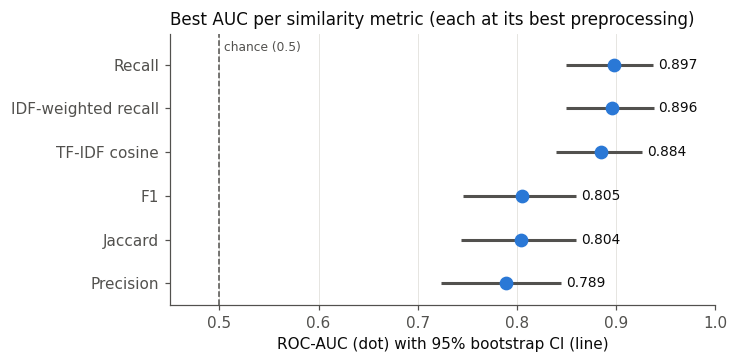

,metric,config,auc,auc_ci_low,auc_ci_high,oracle_acc
0,recall,stop=1 norm=porter lc=1 minlen=2 title=1 metri...,0.897485,0.849729,0.937367,0.832579
1,idf_recall,stop=1 norm=porter lc=0 minlen=2 title=1 metri...,0.895683,0.849116,0.937644,0.846154
2,tfidf_cosine,stop=1 norm=porter lc=1 minlen=1 title=1 metri...,0.884379,0.839096,0.926448,0.814480
3,f1,stop=1 norm=none lc=1 minlen=2 title=1 metric=...,0.805046,0.745920,0.859513,0.746606
4,jaccard,stop=1 norm=none lc=1 minlen=2 title=1 metric=...,0.804022,0.743881,0.859266,0.737557
5,precision,stop=1 norm=porter lc=0 minlen=2 title=1 metri...,0.788540,0.723324,0.844721,0.742081


In [3]:
# Best configuration for each metric = the first row for that metric in grid.csv (grid.csv is sorted by AUC).
best_per_metric = grid.groupby("metric", sort=False).head(1)
bpm = best_per_metric.merge(boot[["config", "auc_ci_low", "auc_ci_high"]], on="config", how="left")
bpm = bpm.sort_values("auc")   # lowest at the bottom of the list -> highest at the top of the plot

fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(bpm))
# Dot = AUC, whisker = 95% bootstrap CI. A dot plot is used (not bars) because the axis does not start at 0.
ax.hlines(y, bpm["auc_ci_low"], bpm["auc_ci_high"], color=INK_2, linewidth=2)
ax.plot(bpm["auc"], y, "o", color=BLUE, markersize=8)
for yi, (auc, hi) in enumerate(zip(bpm["auc"], bpm["auc_ci_high"])):
    ax.text(hi + 0.005, yi, f"{auc:.3f}", va="center", color=INK, fontsize=9)
ax.set_yticks(y, [METRIC_LABELS[m] for m in bpm["metric"]])
ax.axvline(0.5, color=INK_2, linestyle="--", linewidth=1)
ax.text(0.505, len(bpm) - 0.6, "chance (0.5)", color=INK_2, fontsize=8, va="center")
ax.set_xlim(0.45, 1.0)
ax.set_ylim(-0.5, len(bpm) - 0.3)
ax.set_xlabel("ROC-AUC (dot) with 95% bootstrap CI (line)")
ax.set_title("Best AUC per similarity metric (each at its best preprocessing)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "m1_auc_by_metric.png")
plt.show()

bpm.sort_values("auc", ascending=False)[["metric", "config", "auc", "auc_ci_low", "auc_ci_high", "oracle_acc"]]

**How to read it.** The recall-type metrics (recall and IDF-weighted recall) are at the top, TF-IDF cosine is
close behind, and precision, F1 and Jaccard are clearly lower. The individual CIs can overlap a little, but
overlapping CIs do *not* mean "no difference". The right test is the **paired** bootstrap of the difference
(`bootstrap.csv`, used in section 2), which compares both metrics on the same resampled facts.

**Why.** A fact is about 7 words and a passage is hundreds. Precision, F1 and Jaccard all divide by the
**passage** size (Jaccard ≤ |F|/|P|), so their score mostly reflects how long the passage is, not whether it
supports the fact. Recall divides only by the **fact** size: "how many of the claim's words appear in the
evidence?" That matches the question we are asking.

## 2. Ablation: what is each design decision worth?

An **ablation** starts from the chosen configuration and changes exactly **one** setting. The x-axis shows the
resulting change in AUC (Δ AUC); negative means the alternative is worse.

The whisker is the **paired** bootstrap 95% CI of the difference. "Paired" means both configurations are scored
on the same resampled facts, so we measure their difference directly.
- **Blue:** the whole CI is below 0. The chosen setting is *significantly* better.
- **Grey:** the CI crosses 0. The difference could be noise, so the two options are statistically equivalent
  on this data.

saved report\figures\m1_ablation.png


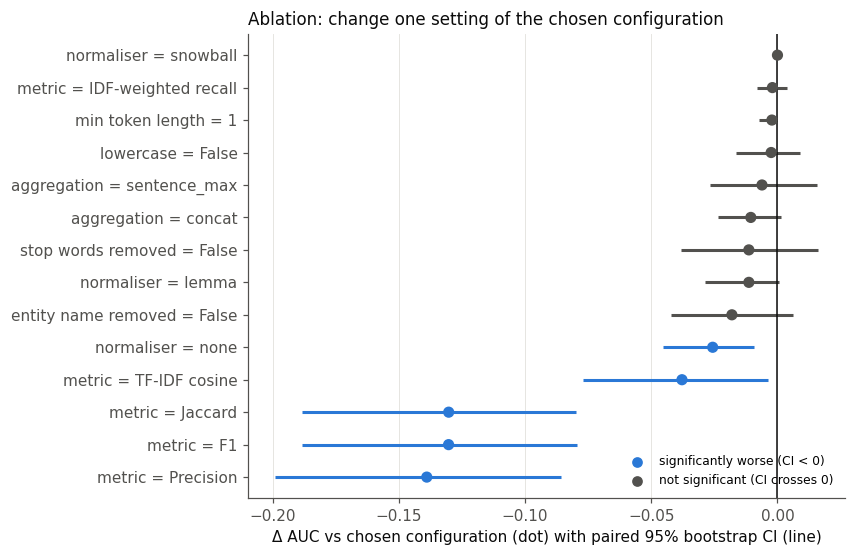

,factor,level,auc,delta_auc,diff_vs_best_ci_low,diff_vs_best_ci_high,significant
0,metric,precision,0.758519,-0.138966,-0.198980,-0.085762,True
1,metric,f1,0.767161,-0.130324,-0.188327,-0.079392,True
2,metric,jaccard,0.767202,-0.130283,-0.188228,-0.079757,True
3,metric,tfidf_cosine,0.859641,-0.037844,-0.077191,-0.003721,True
4,normalizer,none,0.871805,-0.025680,-0.045321,-0.009457,True
5,drop_title,False,0.879423,-0.018062,-0.042058,0.006035,False
6,normalizer,lemma,0.886140,-0.011345,-0.028587,0.000782,False
7,remove_stopwords,False,0.886140,-0.011345,-0.038144,0.015987,False
8,aggregation,concat,0.886918,-0.010567,-0.023547,0.001407,False
9,aggregation,sentence_max,0.891342,-0.006144,-0.026870,0.015811,False


In [4]:
FACTOR_LABELS = {"remove_stopwords": "stop words removed", "normalizer": "normaliser", "lowercase": "lowercase",
                 "min_token_len": "min token length", "drop_title": "entity name removed", "metric": "metric",
                 "aggregation": "aggregation"}
abl = ablation[~ablation["is_best"]].merge(
    boot[["config", "diff_vs_best_ci_low", "diff_vs_best_ci_high"]], on="config", how="left")
abl["label"] = [f"{FACTOR_LABELS[f]} = {METRIC_LABELS.get(l, l)}" for f, l in zip(abl["factor"], abl["level"])]
abl["significant"] = abl["diff_vs_best_ci_high"] < 0
abl = abl.sort_values("delta_auc")

fig, ax = plt.subplots(figsize=(7.0, 0.32 * len(abl) + 1.0))
y = np.arange(len(abl))
colors = np.where(abl["significant"], BLUE, INK_2)
ax.hlines(y, abl["diff_vs_best_ci_low"], abl["diff_vs_best_ci_high"], color=colors, linewidth=2)
ax.scatter(abl["delta_auc"], y, color=colors, s=40, zorder=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, abl["label"])
ax.set_xlabel("Δ AUC vs chosen configuration (dot) with paired 95% bootstrap CI (line)")
ax.set_title("Ablation: change one setting of the chosen configuration", loc="left")
ax.grid(axis="y", visible=False)
ax.scatter([], [], color=BLUE, label="significantly worse (CI < 0)")
ax.scatter([], [], color=INK_2, label="not significant (CI crosses 0)")
ax.legend(loc="lower right", fontsize=8)
save(fig, "m1_ablation.png")
plt.show()

abl.sort_values("delta_auc")[["factor", "level", "auc", "delta_auc", "diff_vs_best_ci_low",
                              "diff_vs_best_ci_high", "significant"]].reset_index(drop=True)

**Average effect of each setting over the whole grid.** The ablation above changes one setting around a single
configuration. The table below instead averages each setting over *all* configurations that use it, which shows
whether an effect holds generally. Each level is averaged over the same set of other settings, so the comparison
is fair.

In [5]:
factor_summary.assign(level=[METRIC_LABELS.get(l, l) for l in factor_summary["level"]]) \
    .style.format({"mean_auc": "{:.4f}", "best_auc": "{:.4f}", "best_oracle_acc": "{:.4f}"}).hide(axis="index")

factor,level,n_configs,mean_auc,best_auc,best_oracle_acc
remove_stopwords,True,144,0.7913,0.8975,0.8416
remove_stopwords,False,144,0.7153,0.8910,0.8462
normalizer,none,72,0.7475,0.8768,0.8190
normalizer,porter,72,0.7565,0.8975,0.8462
normalizer,snowball,72,0.7564,0.8975,0.8462
normalizer,lemma,72,0.7528,0.8862,0.8416
lowercase,True,72,0.7565,0.8975,0.8462
lowercase,False,72,0.7630,0.8957,0.8462
min_token_len,1,72,0.7475,0.8953,0.8371
min_token_len,2,72,0.7565,0.8975,0.8462


## 3. ROC curves: recall vs Jaccard vs TF-IDF cosine

A **ROC curve** sweeps the threshold from high to low. At each threshold it plots:
- **TPR** (true-positive rate) = the share of Supported facts correctly predicted S, against
- **FPR** (false-positive rate) = the share of Not-Supported facts wrongly predicted S.

A curve that hugs the top-left corner is good; the diagonal is chance. **AUC is the area under this curve.**

For a *fair* comparison, all three metrics use **the same** preprocessing and aggregation as the chosen
configuration; only the metric changes. The curves are computed by hand with numpy (no scikit-learn), and we
check that the area under each curve equals the AUC stored in `grid.csv`.

saved report\figures\m1_roc_curves.png


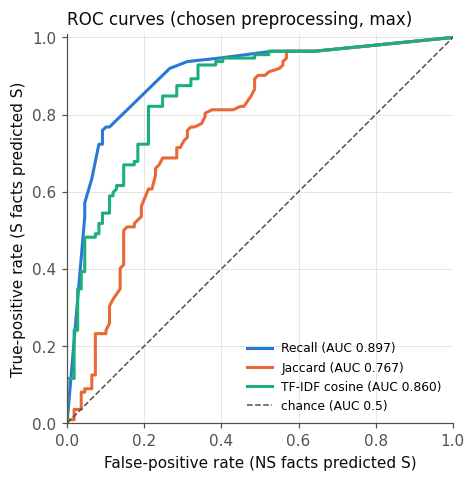

In [6]:
def roc_curve(s, y):
    # Every distinct score is a threshold ("predict S if score >= t"), from the highest to the lowest.
    # Start at (0, 0), where the threshold is above every score and nothing is predicted S.
    thresholds = np.unique(s)[::-1]
    tpr = [((s >= t) & (y == 1)).sum() / (y == 1).sum() for t in thresholds]
    fpr = [((s >= t) & (y == 0)).sum() / (y == 0).sum() for t in thresholds]
    return np.r_[0.0, fpr], np.r_[0.0, tpr]

fig, ax = plt.subplots(figsize=(4.8, 4.6))
for metric, color in [("recall", BLUE), ("jaccard", ORANGE), ("tfidf_cosine", AQUA)]:
    name = CHOSEN.replace("metric=recall", "metric=" + metric)
    fpr, tpr = roc_curve(scores[name].to_numpy(), gold)
    area = np.trapezoid(tpr, fpr)                                # trapezoid rule
    stored = grid.loc[grid["config"] == name, "auc"].item()
    assert abs(area - stored) < 1e-9, (metric, area, stored)     # same number as the Mann-Whitney AUC
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{METRIC_LABELS[metric]} (AUC {stored:.3f})")
ax.plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1, label="chance (AUC 0.5)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect("equal")
ax.set_xlabel("False-positive rate (NS facts predicted S)")
ax.set_ylabel("True-positive rate (S facts predicted S)")
ax.set_title("ROC curves (chosen preprocessing, max)", loc="left")
ax.legend(loc="lower right", fontsize=8)
save(fig, "m1_roc_curves.png")
plt.show()

**How to read it.** Recall rises steeply on the left: many Supported facts are recovered before many
Not-Supported facts slip in. Jaccard stays closer to the diagonal for longer, because its scores depend on
passage length. TF-IDF cosine sits between them.

The long straight segments on the recall curve come from **discrete scores**. With *n* content words, recall
can only be 0, 1/n, 2/n, …, 1, so many facts tie. A group of tied facts switches from NS to S at the same
threshold, which moves TPR and FPR together and draws a diagonal line. For example, the facts at exactly 0.5
form the segment from about (0.1, 0.77) to (0.27, 0.92).

## 4. Score distributions: Supported vs Not Supported

A good score puts Supported facts (blue) on the right and Not-Supported facts (orange) on the left, with little
overlap. Wherever the two colours overlap, *no* threshold can be right for both. Those facts are the errors we
should expect.

The dashed line on the recall panel is the **oracle threshold**: the best threshold on this same data. It is a
*diagnostic only*, because it is fitted on the facts it is evaluated on. **Member 2 chooses the final
threshold.**

saved report\figures\m1_score_distributions.png


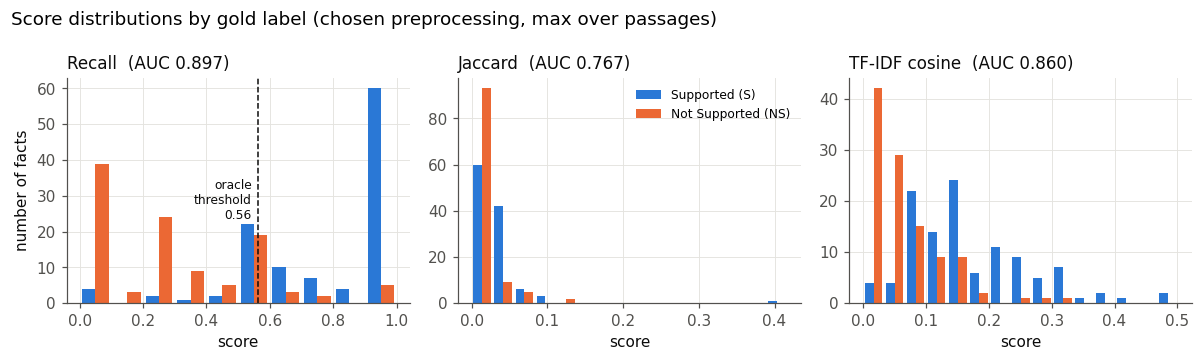

,bin,S,NS
0,"[0.0, 0.1)",4,39
1,"[0.1, 0.2)",0,3
2,"[0.2, 0.3)",2,24
3,"[0.3, 0.4)",1,9
4,"[0.4, 0.5)",2,5
5,"[0.5, 0.6)",22,19
6,"[0.6, 0.7)",10,3
7,"[0.7, 0.8)",7,2
8,"[0.8, 0.9)",4,0
9,"[0.9, 1.0]",60,5


In [7]:
panels = [("recall", "Recall"), ("jaccard", "Jaccard"), ("tfidf_cosine", "TF-IDF cosine")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (metric, title) in zip(axes, panels):
    name = CHOSEN.replace("metric=recall", "metric=" + metric)
    s = scores[name].to_numpy()
    # Recall uses the same 10 bins as the table below. Jaccard/TF-IDF scores are small, so their panels zoom in.
    bins = np.linspace(0, 1, 11) if metric == "recall" else np.linspace(0, max(s.max(), 1e-9), 16)
    counts_s, _ = np.histogram(s[gold == 1], bins=bins)
    counts_ns, _ = np.histogram(s[gold == 0], bins=bins)
    width = (bins[1] - bins[0]) * 0.42
    centres = (bins[:-1] + bins[1:]) / 2
    ax.bar(centres - width / 2, counts_s, width=width, color=BLUE, label="Supported (S)")
    ax.bar(centres + width / 2, counts_ns, width=width, color=ORANGE, label="Not Supported (NS)")
    ax.set_title(f"{title}  (AUC {grid.loc[grid['config'] == name, 'auc'].item():.3f})", loc="left")
    ax.set_xlabel("score")
    if metric == "recall":
        thr = grid.loc[grid["config"] == name, "oracle_threshold"].item()
        ax.axvline(thr, color=INK, linestyle="--", linewidth=1)
        ax.text(thr - 0.02, ax.get_ylim()[1] * 0.55, f"oracle\nthreshold\n{thr:.2f}", ha="right", va="top",
                fontsize=8, color=INK)
axes[0].set_ylabel("number of facts")
axes[1].legend(loc="upper right", fontsize=8)   # the Jaccard panel has free space on the right
fig.suptitle("Score distributions by gold label (chosen preprocessing, max over passages)", x=0.01, ha="left")
fig.tight_layout()
save(fig, "m1_score_distributions.png")
plt.show()

# The same recall distribution as a table (10 equal-width bins), straight from scores_all.csv.
s = scores[CHOSEN].to_numpy()
edges = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(s, edges[1:-1]), 0, 9)
pd.DataFrame({"bin": [f"[{edges[b]:.1f}, {edges[b + 1]:.1f}{']' if b == 9 else ')'}" for b in range(10)],
              "S": [int(((idx == b) & (gold == 1)).sum()) for b in range(10)],
              "NS": [int(((idx == b) & (gold == 0)).sum()) for b in range(10)]})

**How to read it.** Under recall, most Supported facts sit at or near 1.0 and most Not-Supported facts score
below 0.4 (see the table). The overlap is concentrated around **0.5**: facts where exactly half of the content words were found. This is
where word overlap is genuinely uncertain, and where Member 2's threshold choice matters most.

## 5. The preprocessing pipeline on a real example, and what it costs

The pipeline (implemented in `factcheck.py`) runs in this order:

1. **`clean_text`**: remove `<s>`/`</s>` tags, strip accents (é → e), drop possessive `'s`, delete apostrophes,
   and join digit groups (1,000 → 1000).
2. **`tokenize`**: lowercase, then keep runs of letters and digits. Punctuation, hyphens and brackets become
   boundaries.
3. **Stop words and short tokens**: drop function words (NLTK list, negations kept) and stray single letters.
   Numbers are kept.
4. **Porter stemming**: `studied`/`studies` → `studi`. Stop words are removed **before** stemming, because
   Porter turns `was` into `wa`, which would then escape the stop-word list.
5. **Entity name removal**: drop the tokens of the page title (the person's name), because the name matches
   for true and false facts alike.

The cell below runs these steps on a real fact from the dataset (it needs the data folder).

In [8]:
from factcheck import TextPreprocessor, clean_text, tokenize, split_sentences, overlap_recall
from run_grid import load_examples

if not os.path.exists(DATA_DIR):
    print("Data folder not found:", DATA_DIR, "- set CM3604_DATA_DIR to show the live example.")
else:
    examples = load_examples(DATA_DIR)
    no_stem, chosen_pre = TextPreprocessor(normalizer="none"), TextPreprocessor()   # chosen = Porter
    # First Supported fact in the dataset whose tokens are changed by stemming (deterministic choice).
    ex = next(e for e in examples if e.label == "S" and no_stem.process(e.fact) != chosen_pre.process(e.fact))
    title = set().union(*[chosen_pre.process_set(p["title"]) for p in ex.passages])
    stages = [
        ("0. raw fact", ex.fact),
        ("1. clean_text", clean_text(ex.fact)),
        ("2. tokenize (lowercase, regex)", tokenize(ex.fact)),
        ("3. remove stop words + short tokens", no_stem.process(ex.fact)),
        ("4. Porter stemming", chosen_pre.process(ex.fact)),
        ("5. remove entity-name tokens " + str(sorted(title)), [w for w in chosen_pre.process(ex.fact) if w not in title]),
    ]
    display(pd.DataFrame(stages, columns=["step", "result"]).style.hide(axis="index"))

    # Score of this fact against each passage: recall of the remaining fact words, then the max over passages.
    fact_words = set(w for w in chosen_pre.process(ex.fact) if w not in title)
    rows = []
    for i, p in enumerate(ex.passages):
        passage_words = chosen_pre.process_set(p["text"]) - title
        rows.append({"passage": i, "fact words found": sorted(fact_words & passage_words),
                     "recall": overlap_recall(fact_words, passage_words)})
    display(pd.DataFrame(rows).style.format({"recall": "{:.3f}"}).hide(axis="index"))
    print(f"gold label {ex.label}; score = max over passages = {max(r['recall'] for r in rows):.3f} "
          f"(scores_all.csv: {scores.loc[scores['fact'] == ex.fact, CHOSEN].iloc[0]:.3f})")

C:\Users\LENOVO\.conda\envs\cm3604\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


step,result
0. raw fact,Marianne McAndrew is an actress.
1. clean_text,Marianne McAndrew is an actress.
"2. tokenize (lowercase, regex)","['marianne', 'mcandrew', 'is', 'an', 'actress']"
3. remove stop words + short tokens,"['marianne', 'mcandrew', 'actress']"
4. Porter stemming,"['mariann', 'mcandrew', 'actress']"
"5. remove entity-name tokens ['mariann', 'mcandrew']",['actress']


passage,fact words found,recall
0,['actress'],1.000
1,['actress'],1.000


gold label S; score = max over passages = 1.000 (scores_all.csv: 1.000)


**What each normaliser does to individual words.** Stemmers cut suffixes by rule, so they are fast but produce
non-words. The spaCy lemmatiser returns dictionary forms using part-of-speech tags, which handles irregular
verbs (`sang → sing`) but can be surprising (`born → bear`). None of them links `actor`/`actress` or
`Argentinian`/`Argentina`, which is a limit of word overlap itself.

In [9]:
words = ["studied", "studies", "universities", "resides", "born", "sang", "actress", "actor", "1960s", "Argentinian"]
normalisers = {n: TextPreprocessor(remove_stopwords=False, normalizer=n) for n in ["none", "porter", "snowball", "lemma"]}
pd.DataFrame({n: [" ".join(pre.process(w)) for w in words] for n, pre in normalisers.items()}, index=words)

,none,porter,snowball,lemma
studied,studied,studi,studi,study
studies,studies,studi,studi,study
universities,universities,univers,univers,university
resides,resides,resid,resid,reside
born,born,born,born,bear
sang,sang,sang,sang,sing
actress,actress,actress,actress,actress
actor,actor,actor,actor,actor
1960s,1960s,1960,1960s,1960
Argentinian,argentinian,argentinian,argentinian,argentinian


**Execution time.** This is the time to preprocess every unique text in the dataset (facts, passages, sentences
and titles) starting from an empty cache. It is measured inside `run_grid.py` as the **median of 3 passes**,
because a single measurement of about 0.1 s is noisy. Absolute seconds depend on the machine and how busy it
was, so compare the configurations **relative to each other**; differences below about 0.3 s are noise. Scoring is cheap once the text is preprocessed,
because results are cached per text.

saved report\figures\m1_preprocessing_time.png


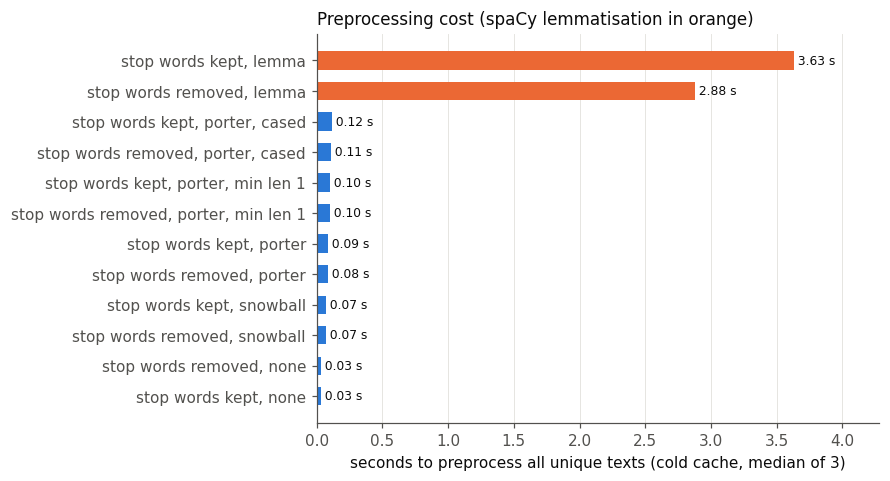

spaCy lemmatisation is 38x slower than Porter stemming on this run.


In [10]:
prep_cols = ["remove_stopwords", "normalizer", "lowercase", "min_token_len"]
timing = grid.drop_duplicates(prep_cols)[prep_cols + ["preprocess_s"]].copy()
timing["setting"] = [f"{'stop words removed' if s else 'stop words kept'}, {n}"
                     + ("" if lc else ", cased") + ("" if ml == 2 else f", min len {ml}")
                     for s, n, lc, ml in zip(timing["remove_stopwords"], timing["normalizer"],
                                             timing["lowercase"], timing["min_token_len"])]
timing = timing.sort_values("preprocess_s")

fig, ax = plt.subplots(figsize=(6.6, 0.3 * len(timing) + 1.0))
y = np.arange(len(timing))
colors = [ORANGE if n == "lemma" else BLUE for n in timing["normalizer"]]
ax.barh(y, timing["preprocess_s"], color=colors, height=0.6)
for yi, v in zip(y, timing["preprocess_s"]):
    ax.text(v, yi, f" {v:.2f} s", va="center", fontsize=8, color=INK)
ax.set_yticks(y, timing["setting"])
ax.set_xlabel("seconds to preprocess all unique texts (cold cache, median of 3)")
ax.set_title("Preprocessing cost (spaCy lemmatisation in orange)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, timing["preprocess_s"].max() * 1.18)
save(fig, "m1_preprocessing_time.png")
plt.show()

lemma = timing.loc[timing["normalizer"] == "lemma", "preprocess_s"].mean()
porter = timing.loc[(timing["normalizer"] == "porter") & timing["lowercase"] & (timing["min_token_len"] == 2),
                    "preprocess_s"].mean()
print(f"spaCy lemmatisation is {lemma / porter:.0f}x slower than Porter stemming on this run.")

## 6. Error analysis of the chosen configuration (diagnostic threshold)

To look at concrete mistakes we need a threshold. We use the **oracle threshold** from `grid.csv` (the best
threshold on this same data). So the accuracy and confusion matrix below are **optimistic diagnostics**, not the
final result. The final threshold and accuracy come from Member 2's validated `predict()` (section 7).

- **False positive (FP):** predicted S, but the gold label is NS. The words are present, but the claim is not
  supported.
- **False negative (FN):** predicted NS, but the gold label is S. The claim is supported, but in different
  words.

The confusion matrix uses the same layout as `factchecking_main.py`: rows are gold [S, NS] and columns are
predictions [S, NS].

saved report\figures\m1_confusion_oracle.png


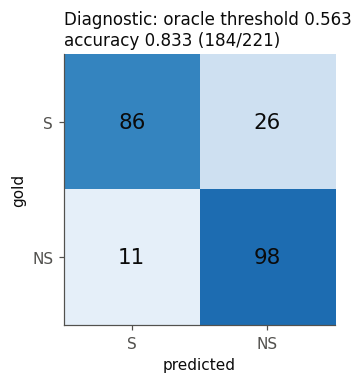

FP = 11, FN = 26


In [11]:
s = scores[CHOSEN].to_numpy()
thr = grid.loc[grid["config"] == CHOSEN, "oracle_threshold"].item()
pred = (s >= thr).astype(int)
cm = np.array([[((gold == 1) & (pred == 1)).sum(), ((gold == 1) & (pred == 0)).sum()],
               [((gold == 0) & (pred == 1)).sum(), ((gold == 0) & (pred == 0)).sum()]])
acc = np.trace(cm) / cm.sum()
assert abs(acc - grid.loc[grid["config"] == CHOSEN, "oracle_acc"].item()) < 1e-12

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.3)   # single-hue sequential scale for counts
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14, color=INK)
ax.set_xticks([0, 1], ["S", "NS"]); ax.set_yticks([0, 1], ["S", "NS"])
ax.set_xlabel("predicted"); ax.set_ylabel("gold")
ax.grid(False)
ax.set_title(f"Diagnostic: oracle threshold {thr:.3f}\naccuracy {acc:.3f} ({np.trace(cm)}/{cm.sum()})", loc="left")
save(fig, "m1_confusion_oracle.png")
plt.show()
print(f"FP = {cm[1, 0]}, FN = {cm[0, 1]}")

In [12]:
# The 10 most confident mistakes of each type, with the content words the score was computed on.
if os.path.exists(DATA_DIR):
    by_fact = {e.fact: e for e in examples}
    def content_words(fact):
        e = by_fact[fact]
        title = set().union(*[chosen_pre.process_set(p["title"]) for p in e.passages])
        kept = [w for w in chosen_pre.process(fact) if w not in title]
        return " ".join(kept if kept else chosen_pre.process(fact))
    table = scores[["fact", "label"]].assign(score=s, predicted=np.where(pred == 1, "S", "NS"),
                                             gold=np.where(gold == 1, "S", "NS"))
    fp = table[(table.gold == "NS") & (table.predicted == "S")].sort_values("score", ascending=False).head(10)
    fn = table[(table.gold == "S") & (table.predicted == "NS")].sort_values("score").head(10)
    for name, df in [("False positives (highest-scoring NS facts)", fp), ("False negatives (lowest-scoring S facts)", fn)]:
        print(name)
        display(df.assign(content_words=[content_words(f) for f in df["fact"]])
                [["fact", "label", "score", "content_words"]].style.format({"score": "{:.3f}"}).hide(axis="index"))

False positives (highest-scoring NS facts)


fact,label,score,content_words
Marianne McAndrew is an American.,NS,1.000,american
Cleveland is in Ohio.,IR,1.000,cleveland ohio
Trivisonno worked at WKNR.,NS,1.000,work wknr
Kerser is from Sydney.,NS,1.000,sydney
He served as a sniper.,NS,1.000,serv sniper
Jidenna's music is a fusion of hip-hop.,NS,0.750,music fusion hip hop
The Fischer Research Laboratory was founded in 1936.,NS,0.750,research laboratori found 1936
He has worked at Mayo Clinic.,NS,0.667,work mayo clinic
Mayo Clinic is an organization.,NS,0.667,mayo clinic organ
"Gerhard Fischer invented the first handheld, battery-operated metal detector in 1931.",NS,0.625,invent first handheld batteri oper metal detector 1931


False negatives (lowest-scoring S facts)


fact,label,score,content_words
Hibo Wardere is based in the United Kingdom.,S,0.000,base unit kingdom
Florencia Bertotti is an Argentinian.,S,0.000,argentinian
They divorced in 1964.,S,0.000,divorc 1964
Haagensen later transitioned to television.,S,0.000,later transit televis
Rio de Janeiro is in Brazil.,S,0.250,rio de janeiro brazil
Haagensen began his acting career in theater.,S,0.250,began act career theater
Haagensen later transitioned to film.,S,0.333,later transit film
He often incorporates African elements into his style.,S,0.400,often incorpor african element style
He often incorporates African elements into his fashion.,S,0.400,often incorpor african element fashion
She has worked to promote the elimination of FGM.,S,0.500,work promot elimin fgm


**Patterns to look for** (useful for Part 3, coordinated by Member 4):
- **FP, the words are there but the relation is not.** Bag-of-words cannot tell "born in X" from "lived in X",
  or "is American" from a passage that mentions America in another context. IR facts, which count as NS, can
  also overlap strongly.
- **FN, paraphrase or different word forms.** "Argentinian" vs the passages' "Argentina"/"Argentine", or
  "United Kingdom" vs the passages' "England"/"London". Stemming cannot bridge these; this is what the
  entailment model in Part 2 is for.
- **FN, evidence missing from the retrieved passages.** For example, "They divorced in 1964." has neither
  "divorc…" nor "1964" in any of its passages. No lexical (or entailment) method can fix a retrieval gap.

## 7. Official run: `factchecking_main.py --mode word_overlap`

This is the graded command, run exactly as the marker will run it. It needs `predict()` and the threshold,
which are **Member 2's** part. Until those exist, this cell reports that the run is not yet available rather than
showing a made-up result.

In [13]:
labels = os.path.join(DATA_DIR, "dev_labeled_ChatGPT.jsonl")
passages = os.path.join(DATA_DIR, "passages_bm25_ChatGPT_humfacts.jsonl")
run = subprocess.run([sys.executable, "factchecking_main.py", "--mode", "word_overlap",
                      "--labels_path", labels, "--passages_path", passages],
                     cwd=REPO_ROOT, capture_output=True, text=True)
lines = run.stdout.splitlines()
acc_line = next((i for i, l in enumerate(lines) if l.startswith("Accuracy:")), None)
if run.returncode == 0 and acc_line is not None:
    # The confusion matrix is printed as two tab-separated rows just before the accuracy line.
    official = np.array([[int(x) for x in lines[acc_line - 2].split("\t")],
                         [int(x) for x in lines[acc_line - 1].split("\t")]])
    print("Official confusion matrix (rows gold S/NS, columns predicted S/NS):\n", official)
    print("\n".join(lines[acc_line:]))
else:
    last_error = (run.stderr.strip().splitlines() or ["(no error output)"])[-1]
    print("Official word_overlap run not available yet (exit code %d): %s" % (run.returncode, last_error))
    print("This is expected until Member 2 implements WordRecallThresholdFactChecker.predict().")

Official word_overlap run not available yet (exit code 1): Exception: Implement me
This is expected until Member 2 implements WordRecallThresholdFactChecker.predict().


## 8. Summary

The cell below prints the headline numbers directly from the saved results, so the report text can be checked
against it.

In [14]:
chosen = grid.iloc[0]
ci = boot.loc[boot["config"] == CHOSEN].iloc[0]
print(f"Chosen configuration : {CHOSEN}")
print(f"AUC                  : {chosen.auc:.4f}  (95% bootstrap CI {ci.auc_ci_low:.3f}-{ci.auc_ci_high:.3f})")
print(f"Oracle accuracy      : {chosen.oracle_acc:.4f} at threshold {chosen.oracle_threshold:.4f}  (diagnostic, optimistic)")
print(f"Mean score S / NS    : {chosen.mean_S:.3f} / {chosen.mean_NS:.3f}")
print("Best AUC per metric  :", ", ".join(f"{METRIC_LABELS[m]} {a:.3f}" for m, a in
                                          zip(best_per_metric["metric"], best_per_metric["auc"])))
sig = abl[abl["significant"]]["label"].tolist()
print("Significantly worse alternatives:", "; ".join(sig) if sig else "none")

Chosen configuration : stop=1 norm=porter lc=1 minlen=2 title=1 metric=recall agg=max
AUC                  : 0.8975  (95% bootstrap CI 0.850-0.937)
Oracle accuracy      : 0.8326 at threshold 0.5635  (diagnostic, optimistic)
Mean score S / NS    : 0.789 / 0.267
Best AUC per metric  : Recall 0.897, IDF-weighted recall 0.896, TF-IDF cosine 0.884, F1 0.805, Jaccard 0.804, Precision 0.789
Significantly worse alternatives: metric = Precision; metric = F1; metric = Jaccard; metric = TF-IDF cosine; normaliser = none
